# Plotting prototypes

Redesigned plots for the tutorials (residuals, residuals by pass, state errors against the covariance, what the data determined, covariance shape, convergence, tracking timeline, editing), prototyped in `plotting_prototype.py` before it moves into `scb.Plotting`. It reads the solutions saved by chapters 6 and 9, so run those first.

What changes from `Plotting.plot_residuals_json`:

- **One row per measurement type**, stations as colors, instead of one tall panel per dataset: stations can be compared directly.
- **A histogram on the right of each row**, against the white-noise curve.
- **A header per row** with the statistics that say whether the fit is consistent: mean, RMS, χ²/n with its expected spread for white noise (1 ± √(2/n)), and the lag-1 autocorrelation, which catches correlated residuals that χ²/n misses.
- **±1σ and ±3σ bands**, points beyond 3σ circled, points beyond the axis shown as edge markers instead of stretching it.
- **Pre-fit residuals far above σ are drawn as a signal** (physical units, no noise bands or histogram).
- Physical units by measurement type (m, mm/s, mHz, RU), one time axis, one legend, a quieter style.

In [1]:
import scarabaeus as scb

from plotting_prototype import plot_residuals  # 🔵 TODO: prototype, to be upstreamed into scb.Plotting

scb.SpiceManager.clear_kernels()
scb.SpiceManager.load_kernel_from_mkfile("orex_approach.tm")  # only for the UTC label of the time axis

## Chapter 6: simulated range and range-rate, three stations

Before:

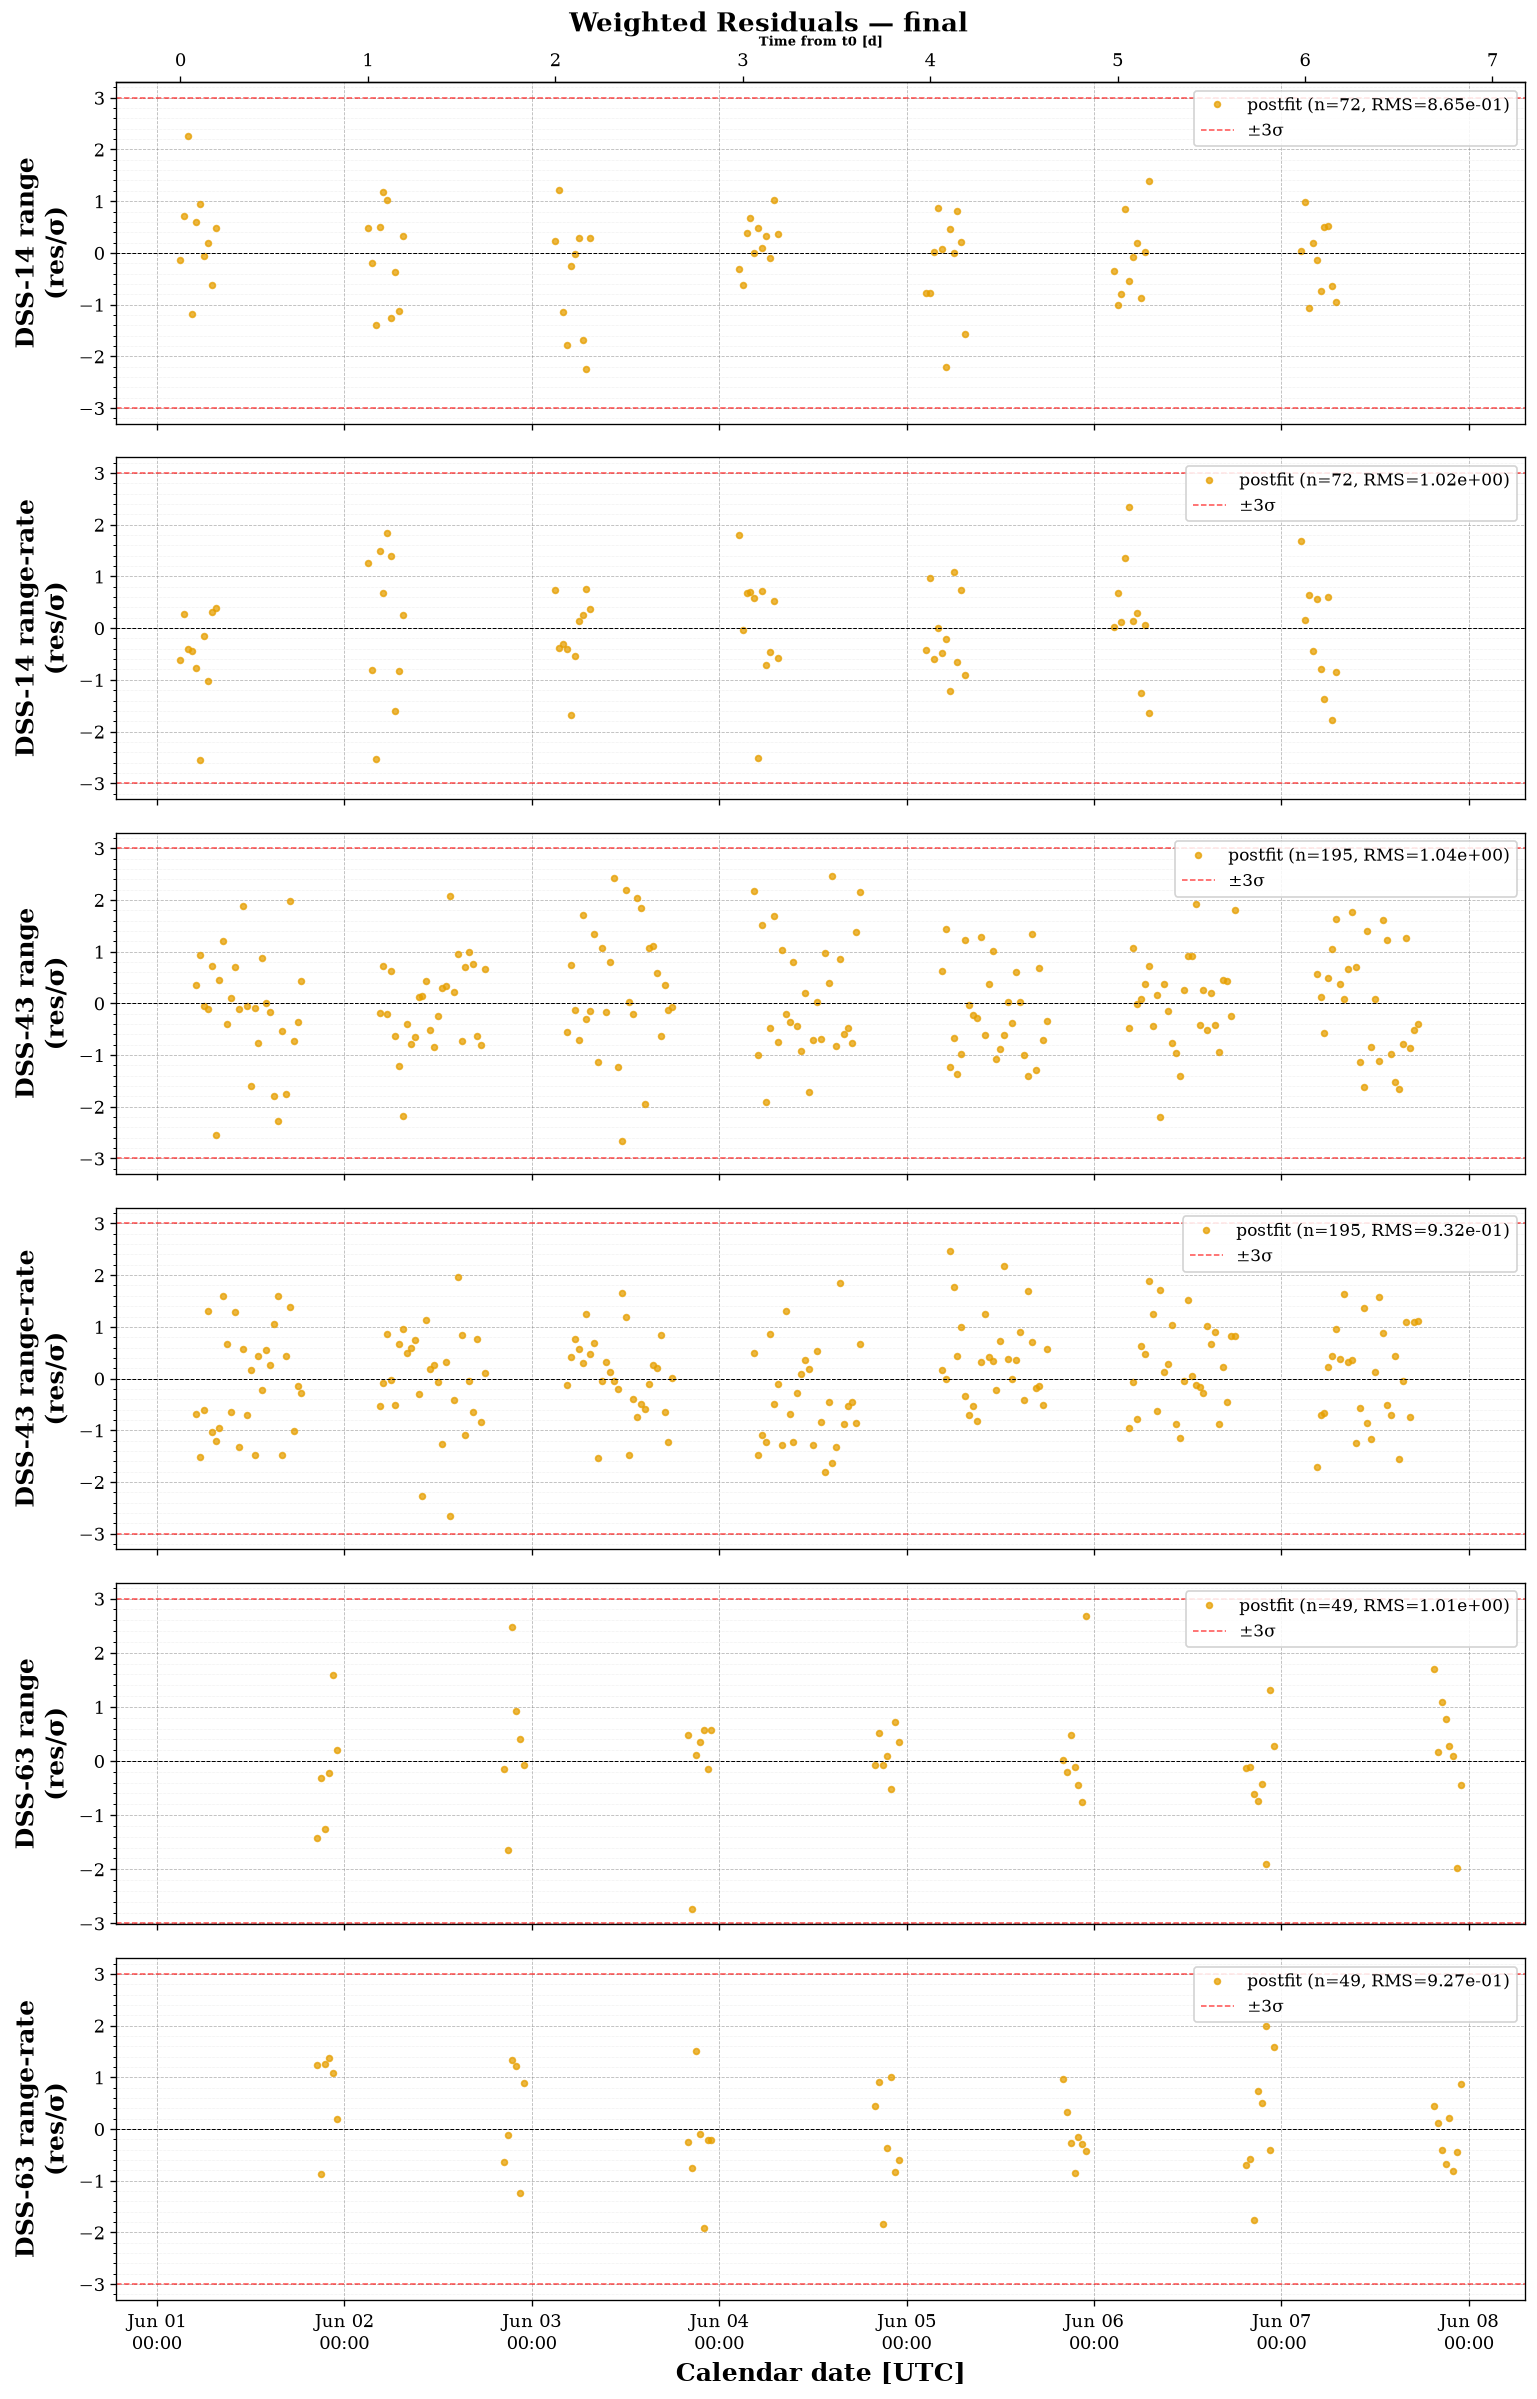

In [2]:
scb.Plotting.plot_residuals_json("outputs/06_first_od_solution/solution.json", iteration="final", kind="postfit",
                                weighted=True, time_unit="day");

After:

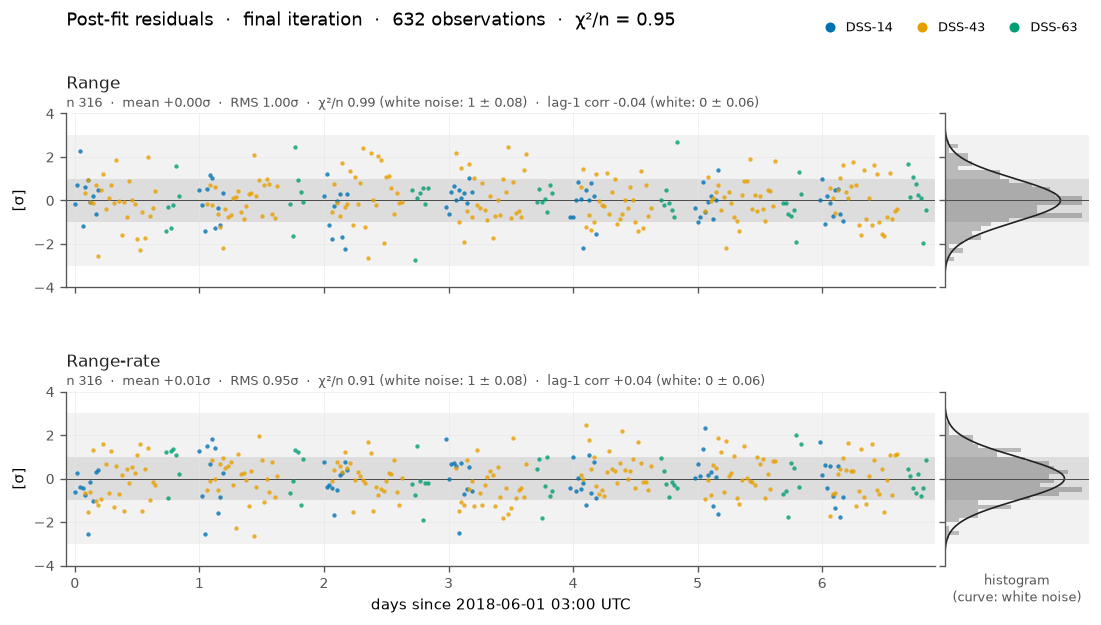

In [3]:
plot_residuals("outputs/06_first_od_solution/solution.json");

Pre-fit residuals of the first iteration: far above the noise, so they are drawn as a signal, in physical units. The range offset grows by about 1.5 km per day, the range-rate offset is constant: a velocity error.

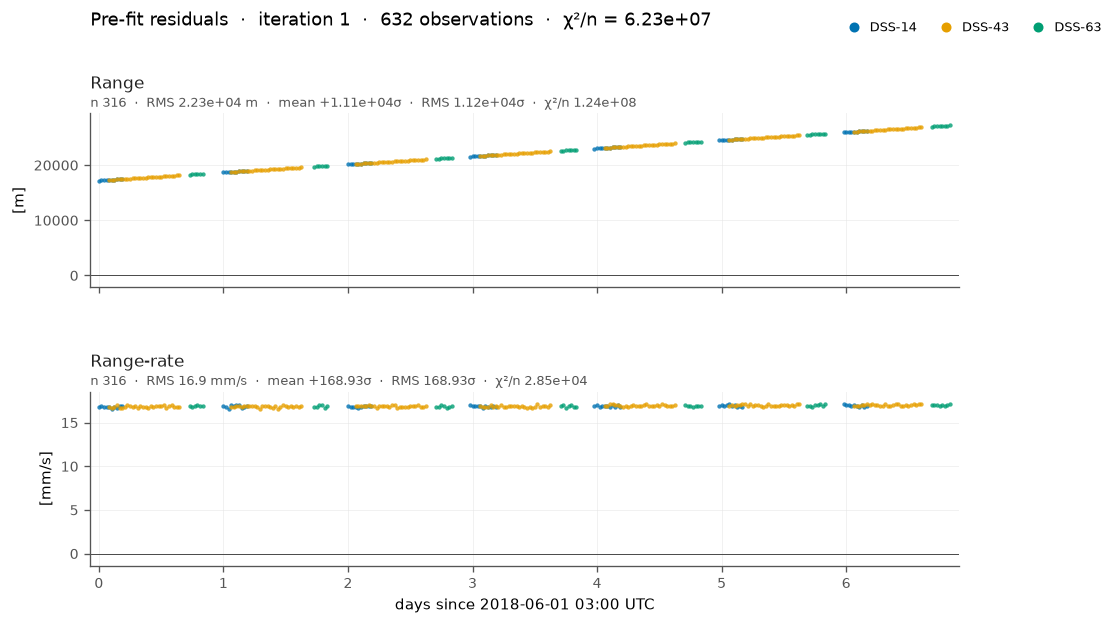

In [4]:
plot_residuals("outputs/06_first_od_solution/solution.json", kind="prefit", iteration="iter_1");

## Chapter 9: real Doppler and ranging, one DSN pass

Before:

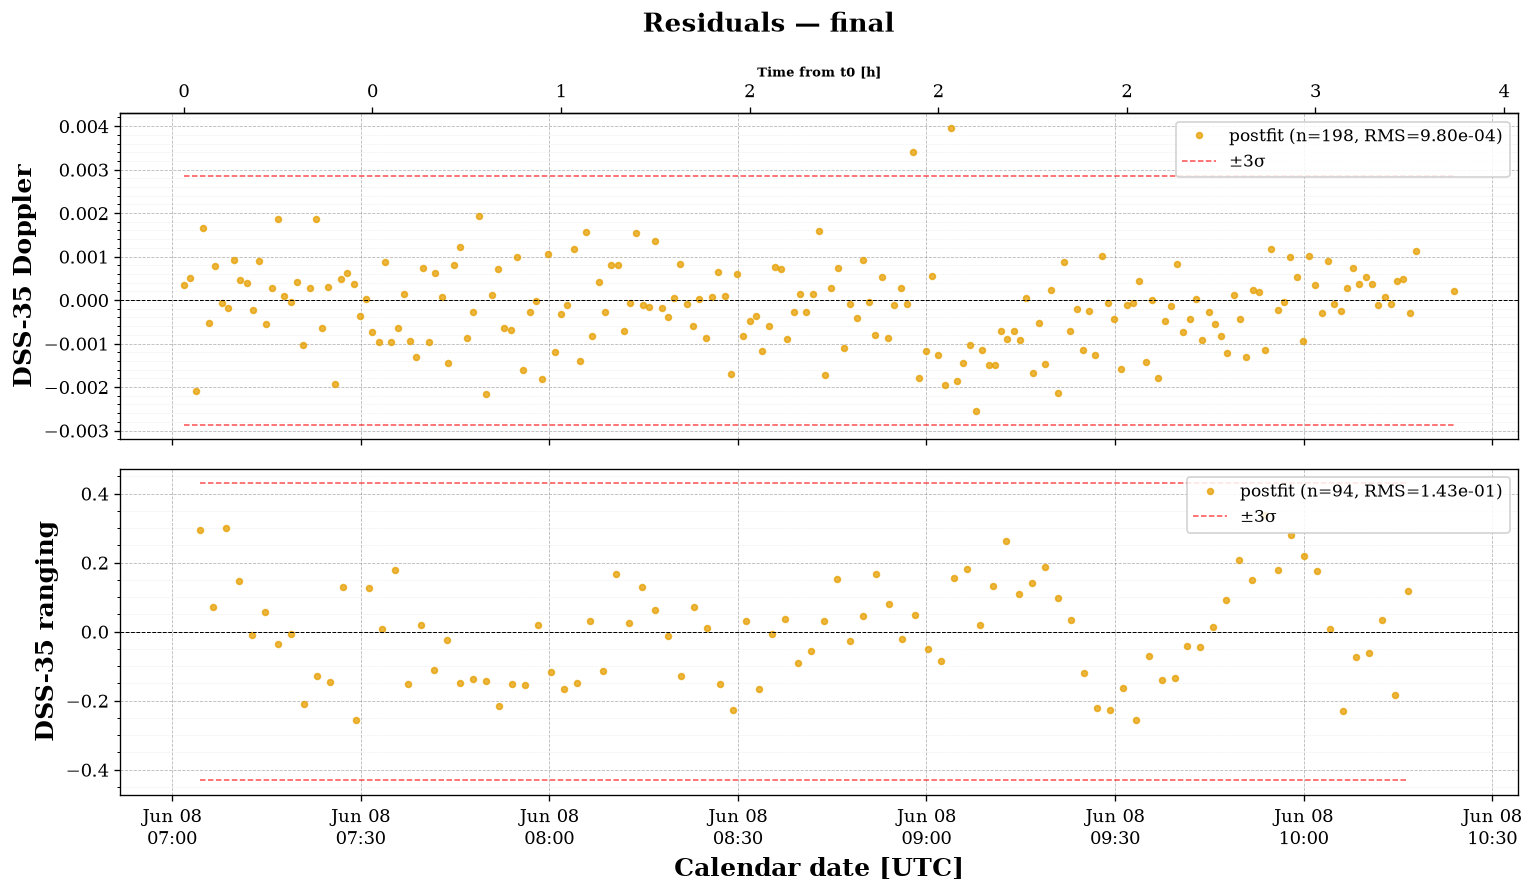

In [5]:
scb.Plotting.plot_residuals_json("outputs/09_real_dsn_data/solution.json", iteration="final", kind="postfit",
                                time_unit="hr");

After, with a running median per pass (`trend=True`). χ²/n is 0.99 for the ranging, yet the running median and the lag-1 autocorrelation (+0.45 against 0 ± 0.10 for white noise) show a systematic signature over the pass: the residuals are not white, which χ²/n alone would not reveal.

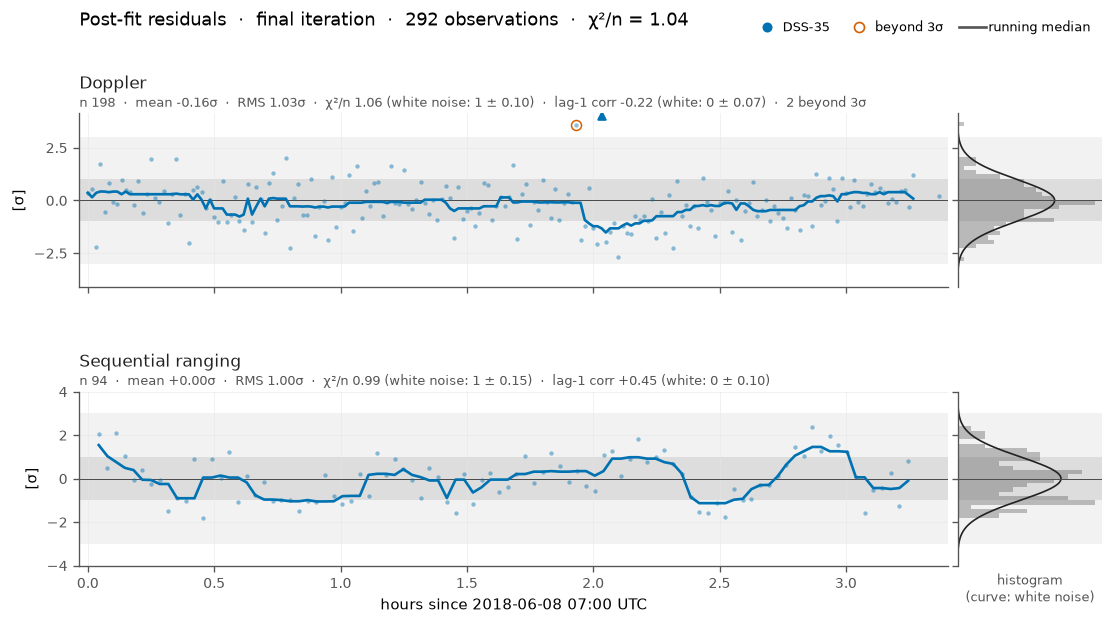

In [6]:
plot_residuals("outputs/09_real_dsn_data/solution.json", trend=True);

The same residuals in physical units:

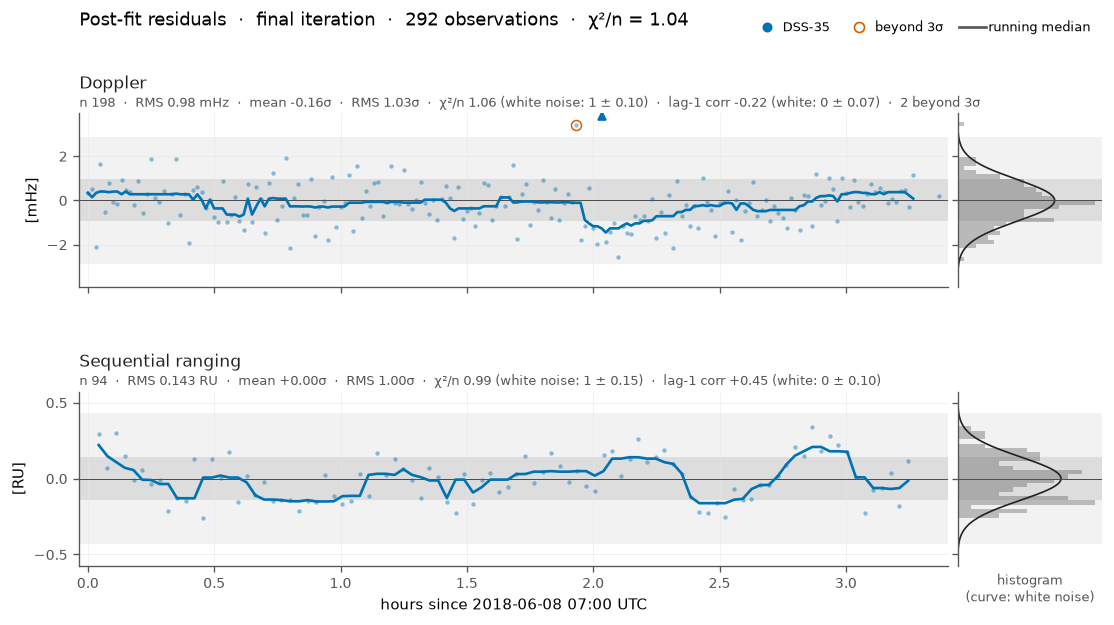

In [7]:
plot_residuals("outputs/09_real_dsn_data/solution.json", normalized=False, trend=True);

## Using it in a notebook

- From a saved solution: `plot_residuals(path_or_loaded_json, kind="postfit" | "prefit", iteration="final" | "iter_<n>")`.
- From memory: `plot_residuals(residuals_from_solution(solution, tracking))`, since in-memory residuals carry no epochs.
- Rows and labels are guessed from the dataset names (`DSS-43 range-rate` → row *Range-rate*, color *DSS-43*); `groups={dataset: (row, label)}` overrides the guess, e.g. to color by pass instead of station.

# State errors against the covariance

`plot_consistency` answers the question every simulated chapter asks: *is the estimation error consistent with the covariance the filter reports?* It replaces the x/y/z panels of `Plotting.plot_state_errors` with:

- **RTN axes of the orbit about Earth**, the natural axes for Earth-based tracking: R is the line of sight, T and N span the plane of sky. Range and Doppler pin R down to meters; T and N to kilometers. In x/y/z the two scales are mixed in every component.
- **Normalized errors e/σ** of the three axes on one shared scale, with ±1σ/±3σ bands and a histogram against N(0, 1).
- **The Mahalanobis distance** χ² = δᵀP⁻¹δ of the 3-D error: one number per epoch, consistent around 3, beyond the 95 % / 99.73 % bounds when the covariance is too optimistic. Its histogram is drawn against the χ²(3) density.
- **Tracking periods shaded and the last measurement marked**, so the fit arc and the prediction read at a glance. Here the evaluation runs three days past the data, to June 11.

`state_errors(solution, truth, epochs)` does the computation (any epochs, inside or after the arc) and can be used without the plot.

Two batch fits on the chapter 6 data: the exact model, and the chapter 8 filter that assumes a 15 m² SRP area instead of 11 m².

In [8]:
%%capture fit_log
# 🔵 TODO: %%capture until the measurement models stop printing progress
from scenario import (TRACKING_DIR, J2000, km, m, minute, mass, cr, models, orex, reference,
                      apriori_state, r_apriori, v_apriori, P0, reference_propagator)
from plotting_prototype import plot_consistency, state_errors

scb.SpiceManager.load_kernel("outputs/02_truth_dynamics/truth.bsp")  # truth to June 11 (ch. 2)
tracking = scb.MeasurementSpec.many(*[
    scb.MeasurementSpec(model=model, dataset_name=model.name,
                        observed_meas=model.observed_measurements(f"{TRACKING_DIR}/{model.name.replace(' ', '_')}.json",
                                                                  units=model.sigma.units))
    for model in models
])

reference_15 = scb.Spacecraft("OREx reference", -64001, mass, scb.ArrayWUnits(15.0, m**2).convert_to(km**2), cr)
state_15 = (scb.StateDefinition()
            .position(reference_15, scb.ArrayWFrame(r_apriori, J2000))
            .velocity(reference_15, scb.ArrayWFrame(v_apriori, J2000)))

hourly = scb.EpochArray.interval(scb.SpiceManager.utc2et("2018-06-01T00:00:00"),
                                 scb.SpiceManager.utc2et("2018-06-11T00:00:00"), dt=scb.ArrayWUnits(60, minute), sys="TDB")
t_pass = scb.EpochArray([scb.SpiceManager.utc2et("2018-06-08T05:55:03")], sys="TDB")  # start of the June 8 DSS-35 pass
solutions, errors, at_pass = {}, {}, {}
for label, spacecraft, state in [("exact model", reference, apriori_state), ("SRP area 15 m², ignored", reference_15, state_15)]:
    srifb = scb.SRIFB(propagator=reference_propagator(spacecraft, state), measurements=tracking,
                      settings=scb.FilterSettings(initial_covariance=P0),
                      traj_name=f"demo_{len(solutions)}.bsp", traj_dir="outputs/plotting_prototype_demo", verbose=False)
    solutions[label], _, _ = srifb.fit(verbose=False)
    # Right after the fit: both fits write their reference trajectory under the same SPICE ID
    errors[label] = state_errors(solutions[label], orex, hourly)
    at_pass[label] = state_errors(solutions[label], orex, t_pass)

**Exact model.** Every axis stays within about 1σ, through the data arc and the three-day prediction, and χ² stays far below its bounds. Its mean (0.7) is below 3, but that is one noise realization of a strongly time-correlated error, not evidence of a pessimistic covariance; a Monte Carlo would test that.

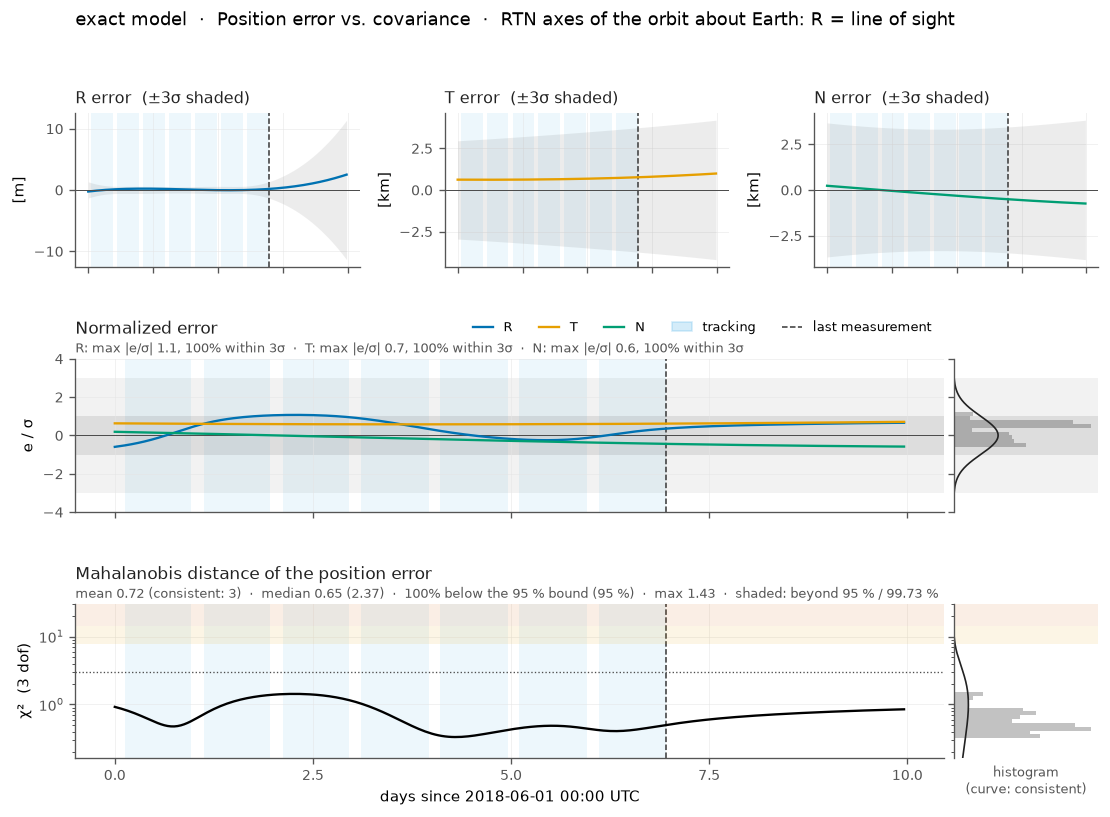

In [9]:
plot_consistency(errors["exact model"], label="exact model");

**SRP area 15 m², ignored.** The plane-of-sky errors (T, N) run to 20–30σ while the line of sight (R) stays near its band until the prediction: the filter absorbs the wrong acceleration where the data are weakest. χ² is in the hundreds except where the errors cross zero around day 3.5, which is why a single epoch can look fine and the whole curve is needed.

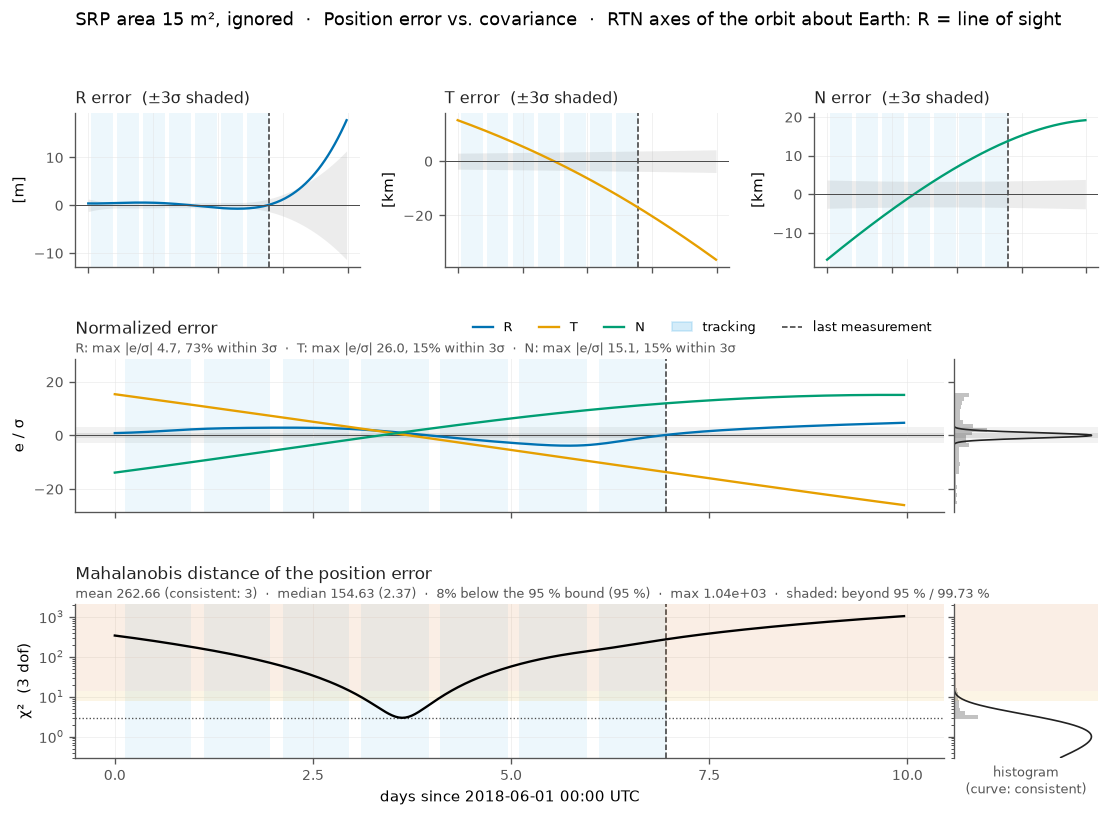

In [10]:
plot_consistency(errors["SRP area 15 m², ignored"], label="SRP area 15 m², ignored");

For comparison, the current library plot of the same solution, in J2000 components:

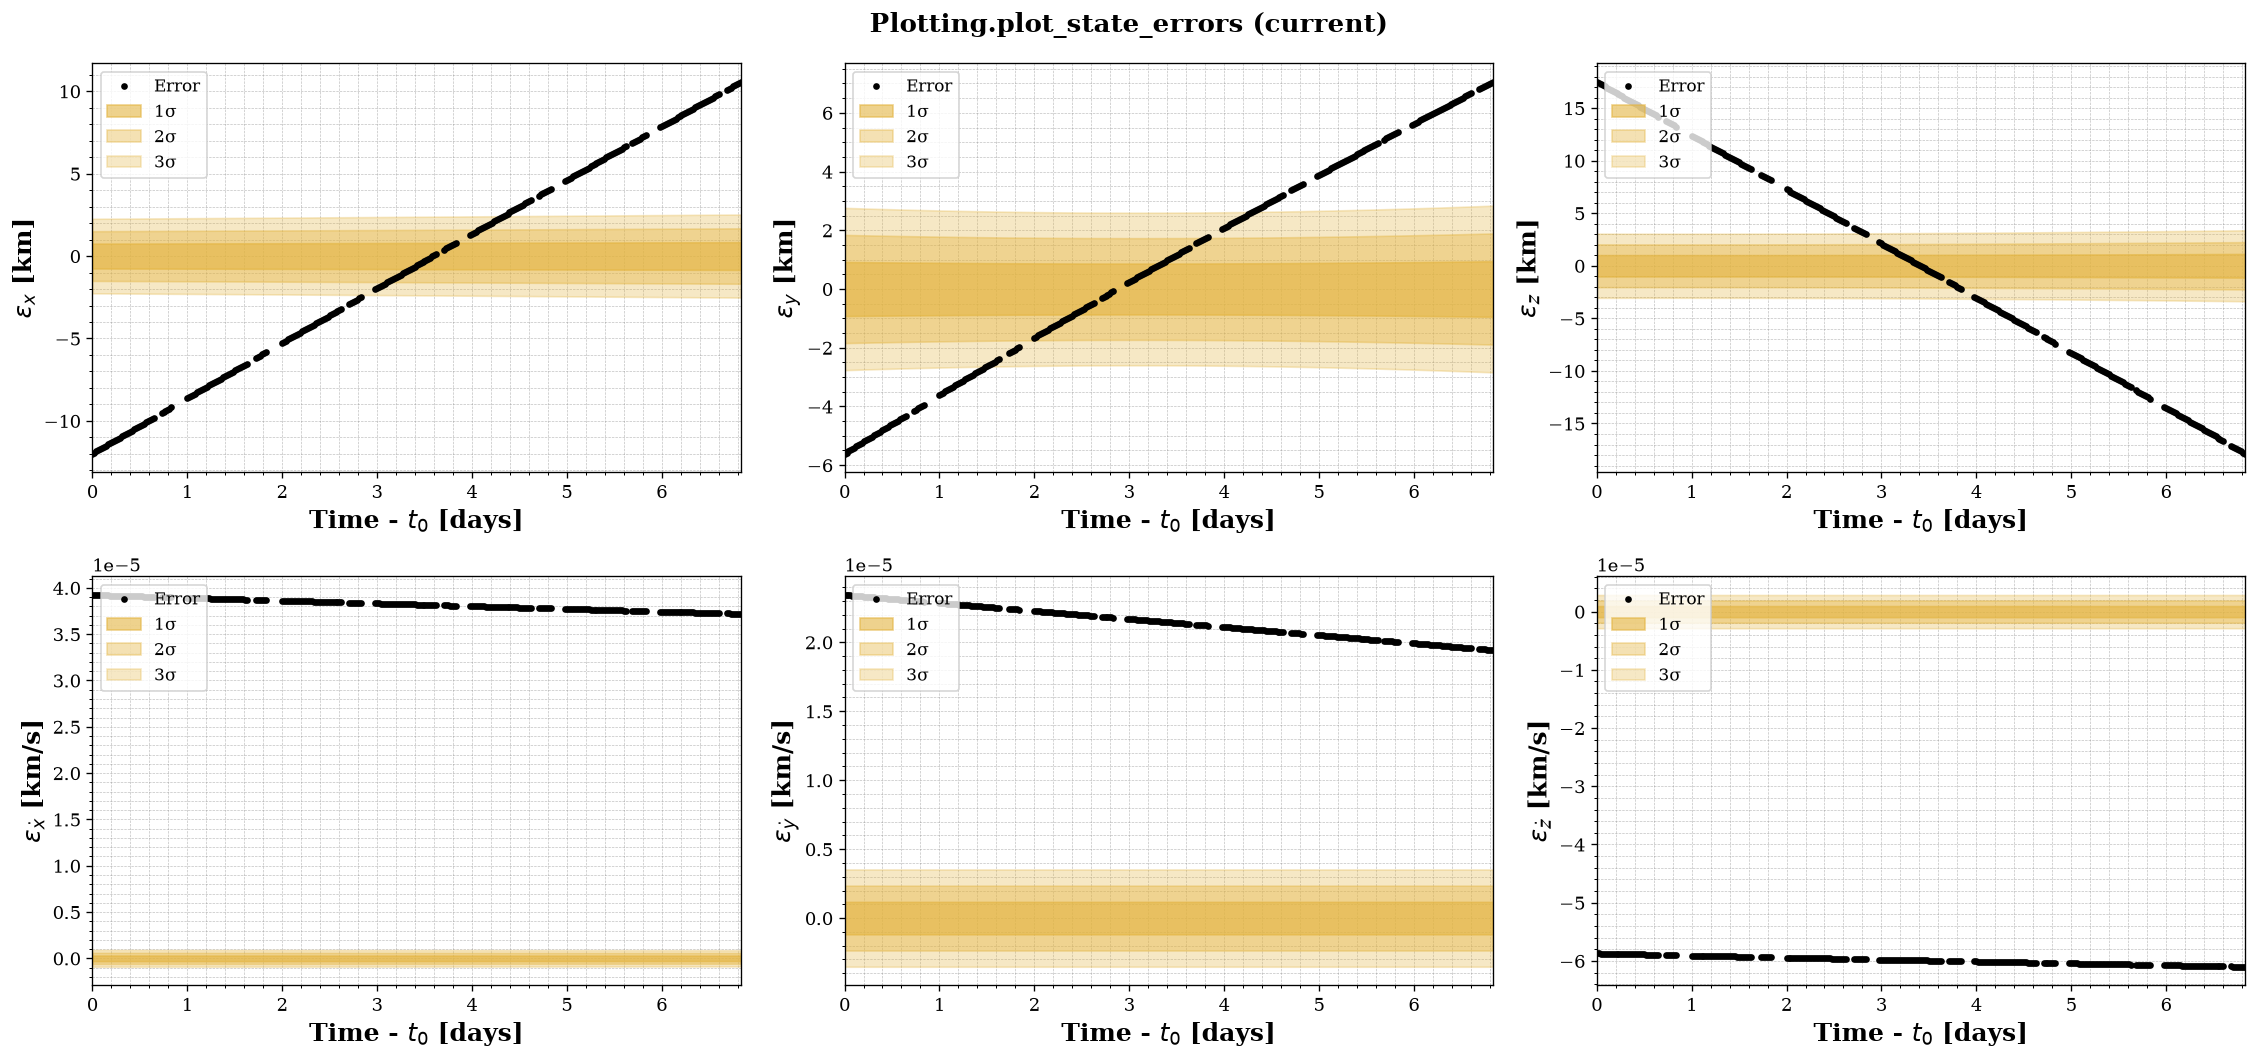

In [11]:
t_solution = scb.EpochArray(solutions["SRP area 15 m², ignored"].timestamps, sys="TDB")
scb.Plotting.plot_state_errors(solutions["SRP area 15 m², ignored"], scb.Trajectory(ref_frame=J2000, origin=scb.CelestialBody.from_constants("SUN"), body=orex),
                               t_solution, n_sigma=3, title="Plotting.plot_state_errors (current)");

# Residuals pass by pass

`plot_residual_summary` condenses the residuals to one row per tracking pass, for campaigns where the full residual plot has too many points to read. For each measurement type it shows the **mean** of the normalized residuals (a bias the fit did not absorb) and their **spread** (the noise level against the weight), each against the band white noise would stay inside for that pass's number of points: ±3/√n for the mean, 1 ± 3/√(2n) for the spread. A thin line joins each station's means, so drifts from pass to pass stand out. Flagged passes are drawn in vermillion.

The same two fits as above (in-memory residuals, via `residuals_from_solution`):

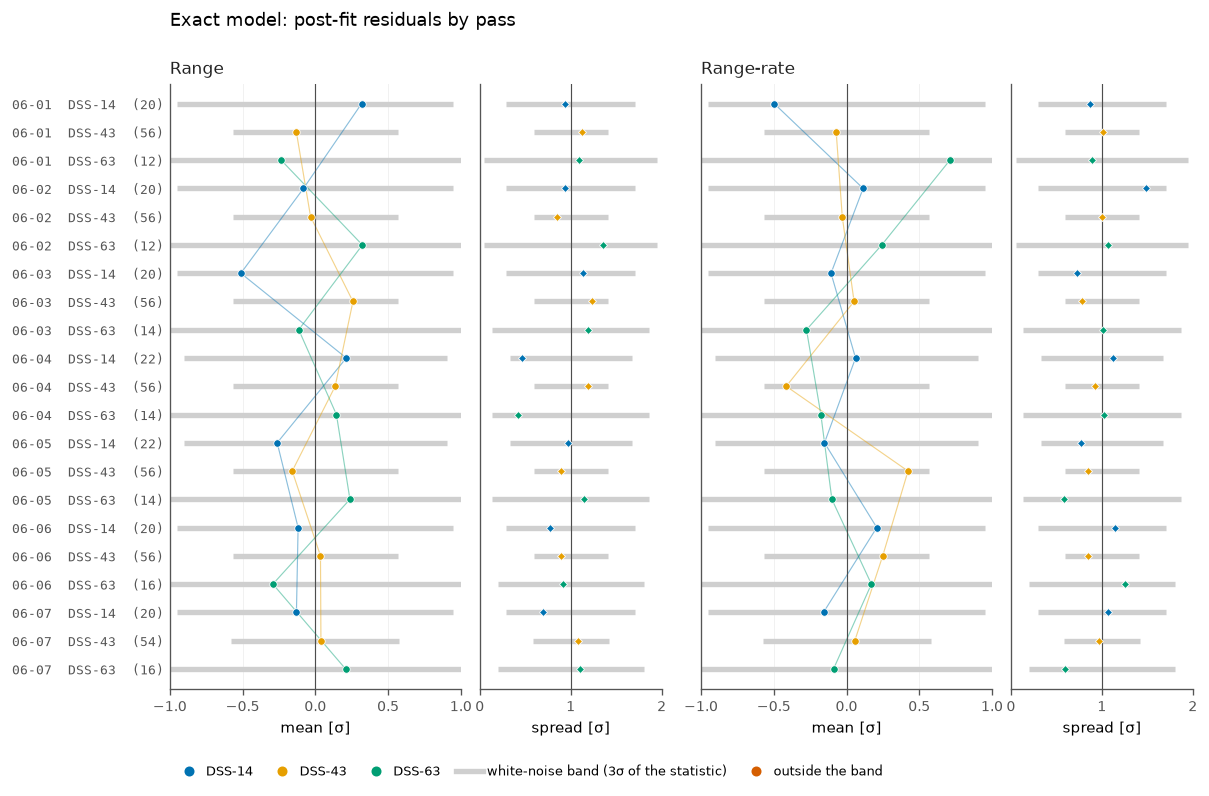

In [12]:
from plotting_prototype import plot_residual_summary, residuals_from_solution

plot_residual_summary(residuals_from_solution(solutions["exact model"], tracking),
                      title="Exact model: post-fit residuals by pass");

**Exact model:** every pass is inside its bands, and the means scatter around zero without a pattern.

**SRP area 15 m², ignored:** over the whole arc the residuals look almost as white as the exact model's (RMS about 1σ), but the passes tell a different story: the first two are biased beyond their bands, and the range means drift steadily over the week (DSS-43 from −0.6σ to +0.5σ, DSS-63 the other way). A dynamics error leaves a systematic pass-to-pass signature that averages out over the arc.

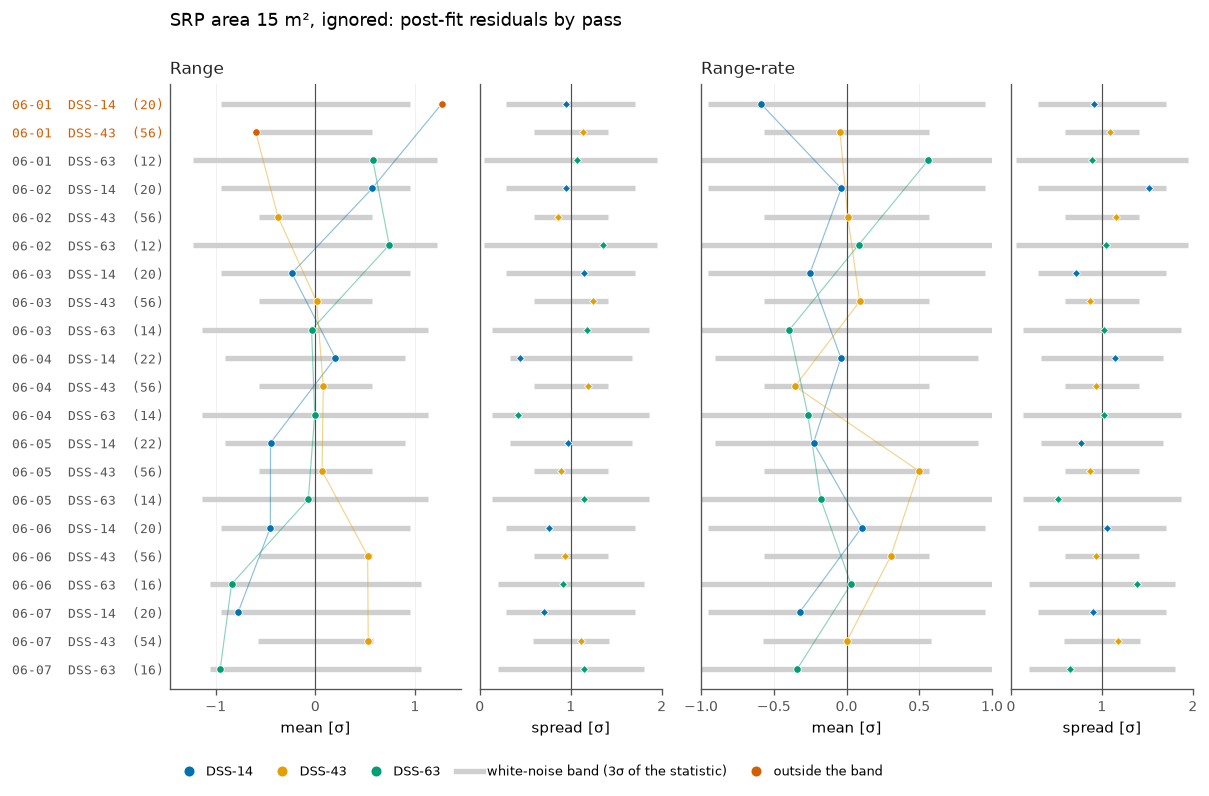

In [13]:
plot_residual_summary(residuals_from_solution(solutions["SRP area 15 m², ignored"], tracking),
                      title="SRP area 15 m², ignored: post-fit residuals by pass");

# What the data determined

`plot_parameter_learning` compares the solution with its a priori, element by element, at the solution epoch. It reads only the saved solution, which records both.

- **Information from the data:** σ_posterior / σ_a priori, on a log scale. Near 1 (the shaded zone), the data added nothing and the estimate is the a priori; far below 1, the data determined the quantity.
- **Estimate against the a priori:** how far the estimate moved, in units of the a-priori σ, with the posterior ±1σ as a bar and the truth as a diamond (orange when it is more than 3σ from the estimate).
- **The values**, a priori → estimate in physical units.

Position and velocity are in the RTN axes of the orbit about Earth, as in `plot_consistency`, so the line-of-sight and plane-of-sky components separate.

**Chapter 8: the SRP scale factor, estimated and considered** (filter area 15 m², truth 11 m², so the true η is 11/15):

In [14]:
%%capture fit_log
from scenario import apriori_sigmas, epochs

eta_fits = {}
for how, sigma_eta in [("estimated", 0.5), ("considered", 0.3)]:
    state = (scb.StateDefinition()
             .position(reference_15, scb.ArrayWFrame(r_apriori, J2000))
             .velocity(reference_15, scb.ArrayWFrame(v_apriori, J2000))
             .param("eta_srp", reference_15, scb.ArrayWFrame(scb.ArrayWUnits([1.0], None), J2000),
                    estimation=how, dynamics="static"))
    settings = scb.FilterSettings(initial_covariance=scb.CovarianceMatrix(
        apriori_sigmas + [scb.ArrayWUnits(sigma_eta, None)], epochs[0], from_list=True))
    srifb = scb.SRIFB(propagator=reference_propagator(reference_15, state), measurements=tracking, settings=settings,
                      traj_name=f"eta_{how}.bsp", traj_dir="outputs/plotting_prototype_demo", verbose=False)
    solution, _, _ = srifb.fit(verbose=False)
    eta_fits[how] = f"outputs/plotting_prototype_demo/eta_{how}.json"
    at_pass[f"15 m², η {how}"] = state_errors(solution, orex, t_pass)  # right after the fit, as above
    solution.save(eta_fits[how])

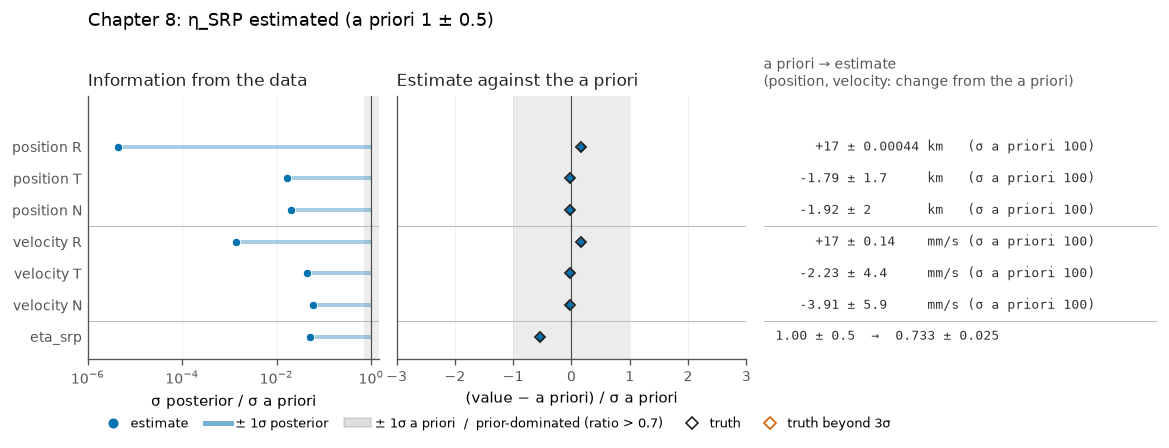

In [15]:
from plotting_prototype import plot_parameter_learning

plot_parameter_learning(eta_fits["estimated"], truth=orex, truth_values={"eta_srp": 11 / 15},
                        title="Chapter 8: η_SRP estimated (a priori 1 ± 0.5)");

A week of tracking determines the line-of-sight position R to under a meter (from a 100 km a priori), the plane-of-sky position to about 2 % of its a priori, and η_SRP to 5 % of its a priori: η moves by half an a-priori σ, from 1 to 0.733, against the true 0.733. Every truth diamond sits on its estimate.

With η **considered**, its value stays at the a priori by construction (gray). The posterior σ here include its uncertainty (the consider covariance, as in `plot_consistency`), so the plane-of-sky estimates, which absorb the SRP error, are uncertain at the 10–20 km level and the truths fall inside them.

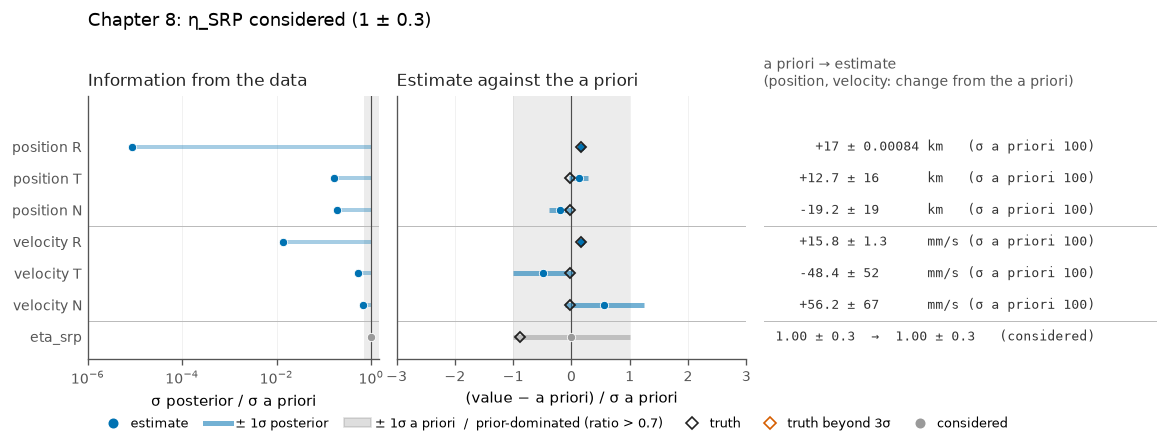

In [16]:
plot_parameter_learning(eta_fits["considered"], truth=orex, truth_values={"eta_srp": 11 / 15},
                        title="Chapter 8: η_SRP considered (1 ± 0.3)");

**Chapter 9: one real pass, Doppler and ranging with a range bias.** The truth is the flight reconstruction. A single pass determines the line-of-sight position and velocity (σ reduced about 100 and 50 times) and part of the plane-of-sky position, leaves the normal velocity at its a priori, and adds nothing to the range bias: its σ stays at 2000 RU. The bias and the line-of-sight position are not separable on one pass, so the data fix their sum and the a priori sets how it is shared.

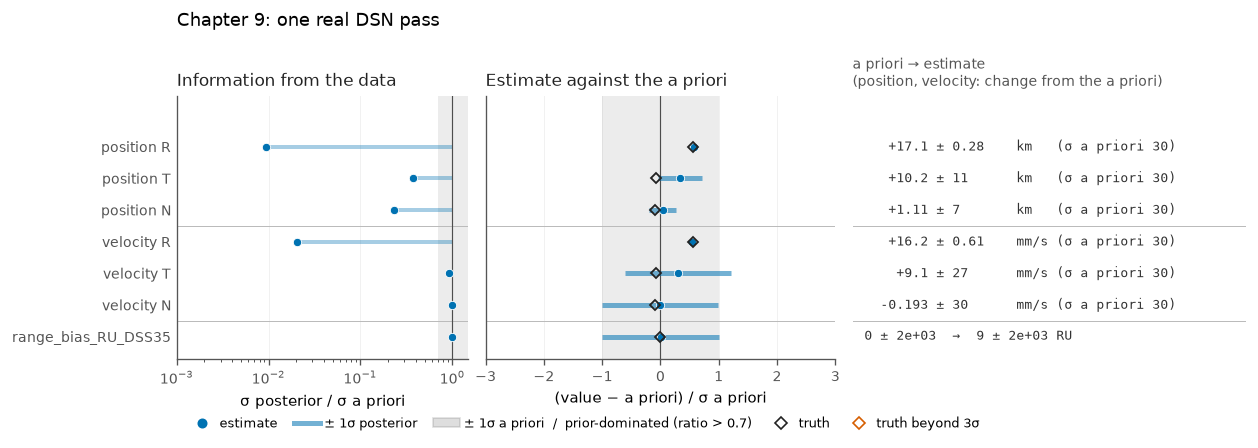

In [17]:
plot_parameter_learning("outputs/09_real_dsn_data/solution.json", truth=scb.Spacecraft("OSIRIS-REx (flight)", -64),
                        title="Chapter 9: one real DSN pass");

# Covariance shape

`plot_covariance_shape` compares several solutions at one epoch, here the start of the June 8 DSS-35 pass, with their actual errors. The plane of sky (T, N) and the line of sight (R) get separate panels because they differ by three orders of magnitude: kilometers against meters. When one ellipse dwarfs the others, an inset zooms on the small ones. Each solution has its own marker, since two can share an estimate.

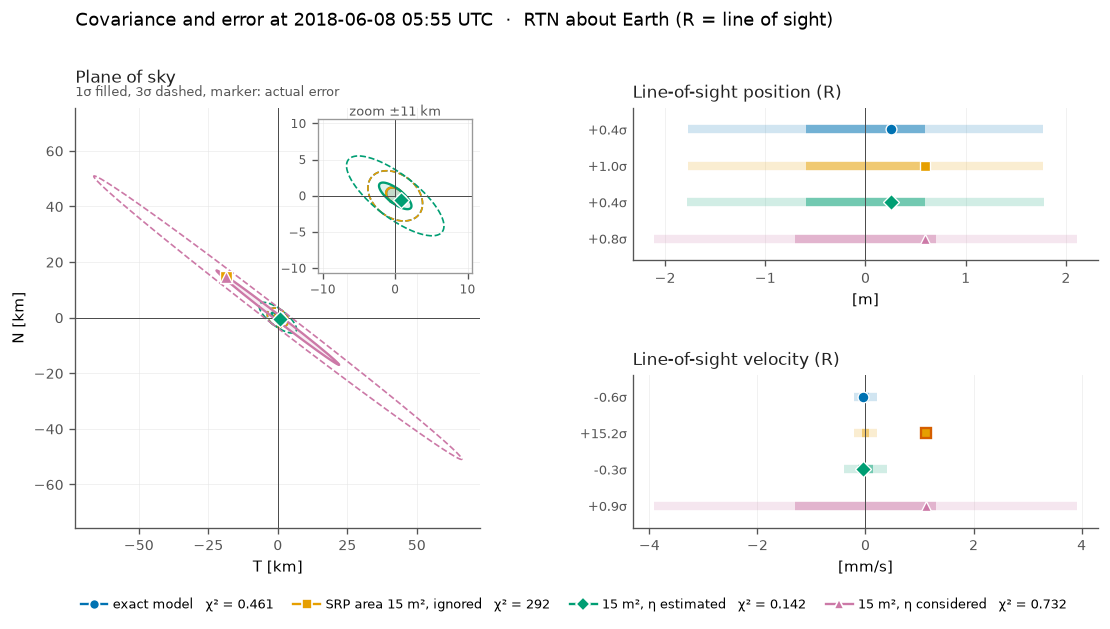

In [18]:
from plotting_prototype import plot_covariance_shape, plot_correlation

plot_covariance_shape(at_pass);

- **Exact model and η estimated:** small ellipses (a few km across the line of sight, under a meter along it) with the error inside, χ² well below the 95 % bound of 5.99.
- **Ignored:** the same ellipse as the exact model, but the error is 20 km away in the plane of sky (χ² ≈ 300) and the line-of-sight velocity is 15σ off: the first minutes of real Doppler would reject this prediction.
- **Considered:** the same estimate as the ignored case (η is not adjusted, so their markers overlap), but an ellipse stretched to tens of km along the direction the SRP error pushes the solution, which now contains the error.

`plot_correlation` shows the correlation matrix of one solution at its epoch, position and velocity in RTN. Correlations near ±1 mark quantities the data cannot separate.

**η estimated:** η is determined (to 5 % of its a priori), but almost entirely through the plane-of-sky velocity: its correlations with the T and N velocity are −0.99 and +0.97. Over a week, a constant SRP acceleration and an initial plane-of-sky velocity error produce nearly the same drift, and the data separate them only through the small difference. The line-of-sight position stays almost uncorrelated with everything: range measures it directly.

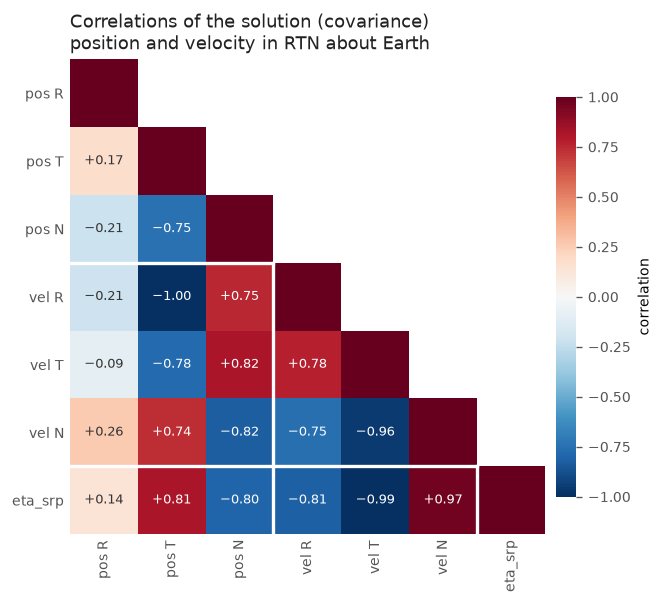

In [19]:
plot_correlation(eta_fits["estimated"]);

**One real pass with a range bias:** the bias and the line-of-sight position are correlated at −1.00. A single pass constrains only their sum (the measured range), so the a priori decides how it is shared between them (compare *What the data determined* above, where the bias σ stays at its a priori). The plane-of-sky position T and the line-of-sight velocity are also at −1.00: a plane-of-sky error tilts the line of sight, and the velocity along it compensates to keep the Doppler fitted.

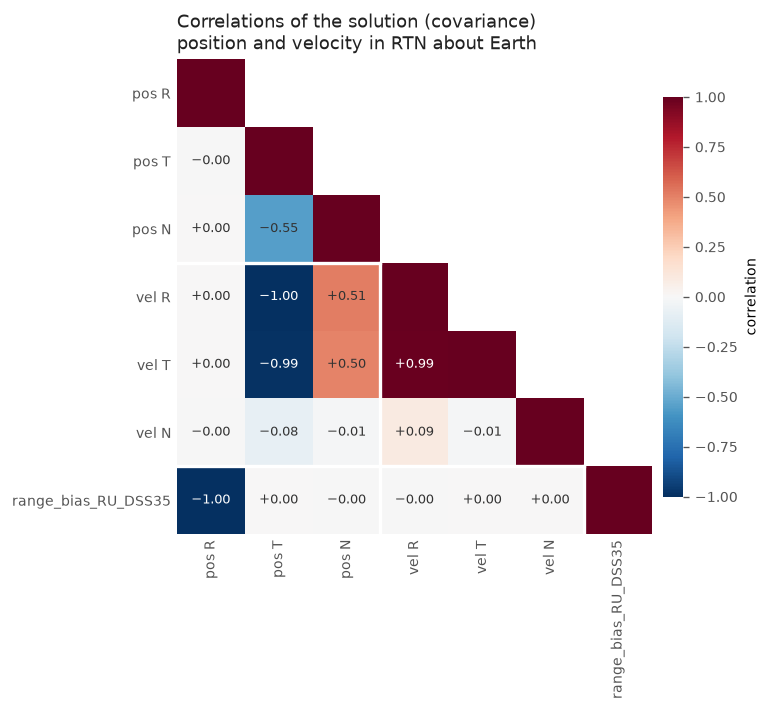

In [20]:
plot_correlation("outputs/09_real_dsn_data/solution.json");

# Convergence

`plot_convergence` reads the convergence record the saved solution keeps for every iteration. Top row: the cost (χ²/n) of the pre-fit residuals on each iteration's reference (hollow) and of the post-fit residuals (filled); then the two tests `fit()` applies, the RMS of the state correction and the relative change of the cost, each against its threshold, with passing iterations filled in green. The title says which test stopped the fit. Bottom row: the pre-fit RMS of each dataset.

**Chapter 6:** the first iteration removes the a-priori error (pre-fit cost from about 6×10⁷ to 0.95), and the second stops on the cost test. The correction of the second iteration, 3×10⁻⁵, is still above the 10⁻⁵ deviation threshold.

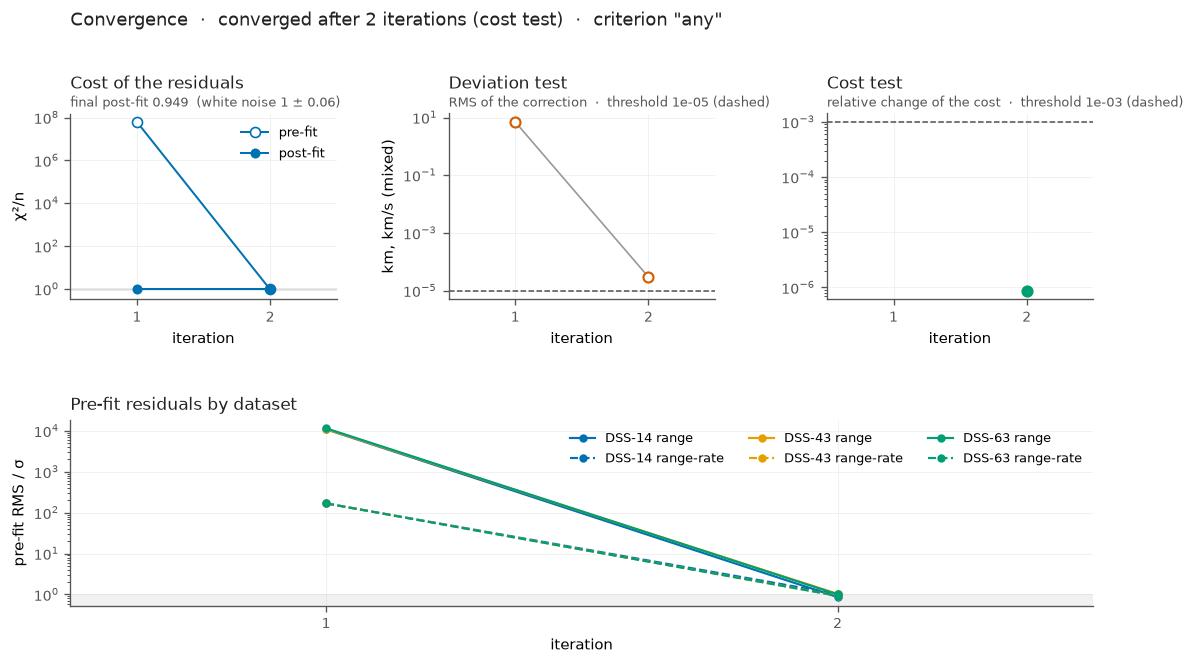

In [21]:
from plotting_prototype import plot_convergence

plot_convergence("outputs/06_first_od_solution/solution.json");

**Chapter 9, one real pass:** after the second iteration the cost is flat at 1.036, but the state correction never settles: it stays between 4 and 13 m per iteration (10⁻² km), four orders of magnitude above the deviation threshold. The fit stops at iteration 5 only because the cost test passes. With `convergence_criterion="deviation"` it would run to `max_iterations`. One pass does not constrain the plane-of-sky position, so the reference keeps sliding along a direction the data cannot see while the residuals stay the same: the deviation test is the wrong test for a weakly observable problem, and this plot shows it at a glance.

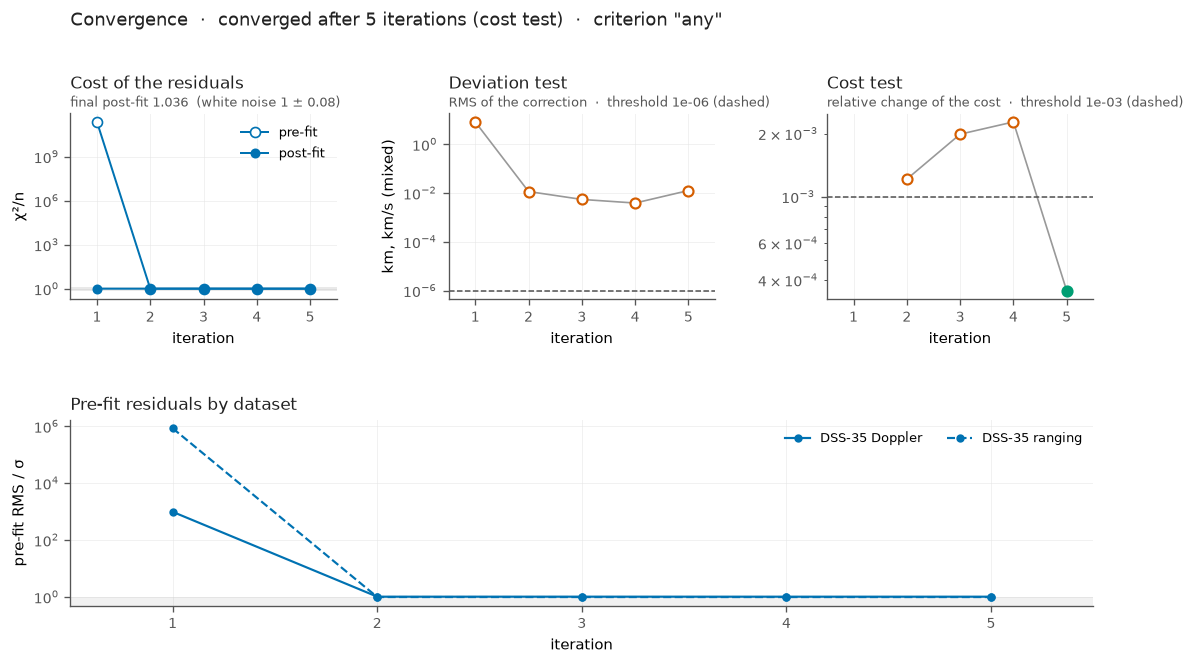

In [22]:
plot_convergence("outputs/09_real_dsn_data/solution.json");

**A fit that does not converge:** the 15 m² filter with SNC process noise (σ = 10⁻¹⁰ km/s², sequential `SRIF`), run with `convergence_criterion="deviation"` and at most 8 iterations. The title turns vermillion.

In [23]:
%%capture fit_log
from scenario import sec

snc = scb.ProcessNoiseSettings(type="SNC", Q_cont=scb.CovarianceMatrix([scb.ArrayWUnits(1e-10, km / sec**2)] * 3,
                                                                       epochs[0], from_list=True))
srif = scb.SRIF(propagator=reference_propagator(reference_15, state_15), measurements=tracking,
                settings=scb.FilterSettings(initial_covariance=P0, process_noise=snc),
                traj_name="snc_deviation.bsp", traj_dir="outputs/plotting_prototype_demo", verbose=False)
solution_snc, n_snc, converged_snc = srif.fit(max_iterations=8, convergence_criterion="deviation", verbose=False)
solution_snc.save("outputs/plotting_prototype_demo/snc_deviation.json")

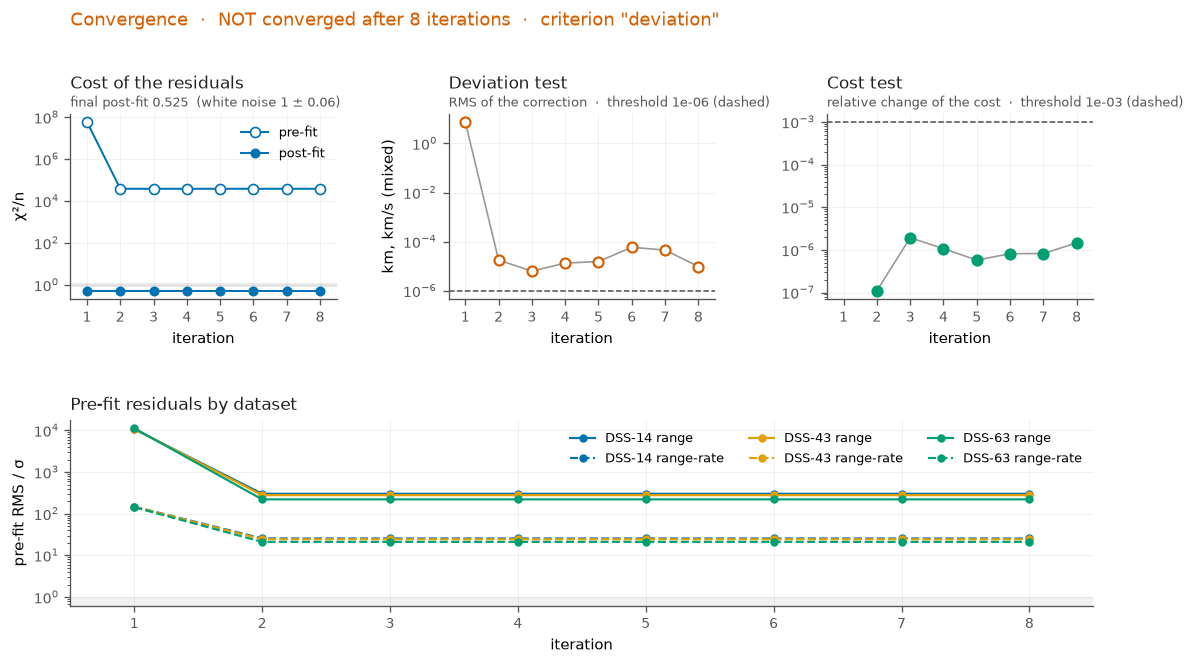

In [24]:
plot_convergence("outputs/plotting_prototype_demo/snc_deviation.json");

Three things the plot shows at once:

- **The cost test passes from iteration 2** (relative changes of 10⁻⁷ to 10⁻⁶), so with the default criterion `"any"` the fit would have stopped there. The deviation test never does: the correction wanders between 6×10⁻⁶ and 6×10⁻⁵ km (6–60 mm) against a 10⁻⁶ threshold, so the run hits `max_iterations`.
- **Pre- and post-fit costs never meet** (3.9×10⁴ against 0.53), unlike the batch fits above. With process noise, the filter's estimate follows stochastic accelerations that the deterministic reference trajectory, re-propagated from the corrected initial state, does not include. The pre-fit residuals on that reference therefore stay large: for a sequential filter with process noise they measure the reference, not the fit.
- **The post-fit cost, 0.53, is below the white-noise band:** the process noise lets the filter follow part of the measurement noise.

# Tracking timeline

`plot_tracking_timeline` shows, per station, when the spacecraft is above the elevation mask (the band, darker at higher elevation), when it is only above the horizon (gray line), and when data were taken (ticks: range on top, range-rate or Doppler below). The left margin gives the fraction of time visible and the number of observations. A geometry strip on top shows the Sun–Earth–probe angle (the solar corona degrades radiometric data below about 15°) and the Earth range.

**The simulated week of chapter 3:** the spacecraft is observed every 30 minutes whenever it is above the mask. Canberra has the longest and highest passes at this southern declination.

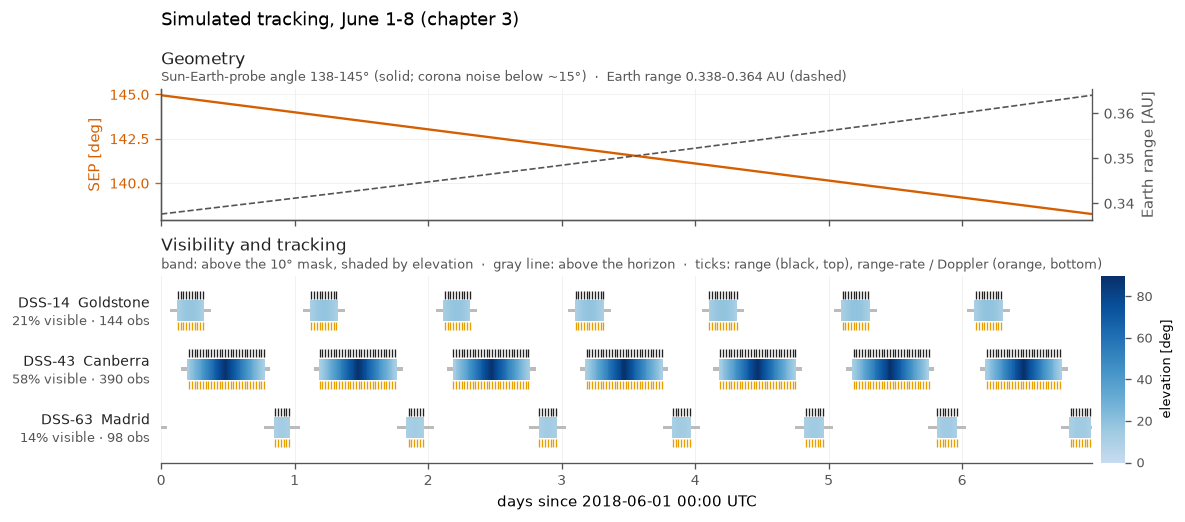

In [25]:
from plotting_prototype import plot_tracking_timeline, epochs_from_tracking_files
from scenario import stations, epochs

grid = scb.EpochArray.interval(epochs[0], epochs[-1], dt=scb.ArrayWUnits(10, minute), sys="TDB")
plot_tracking_timeline(stations, orex, grid, observations=tracking, title="Simulated tracking, June 1-8 (chapter 3)");

**The real DSN passes of June 7–8**, the three passes in the tutorial data, against the flight reconstruction. Real tracking is scheduled, not geometric: DSS-35 could see the spacecraft for about 14 hours on June 8 and tracked it for about 5, the June 7 morning window and Goldstone took no data, and the isolated ticks just before each pass are rows at the start of the files, ranging and Doppler, the kind chapter 9 flags or edits before fitting. With the June 8 evening DSS-65 pass, these are the candidates for the real-data chapters' fit-and-predict test.

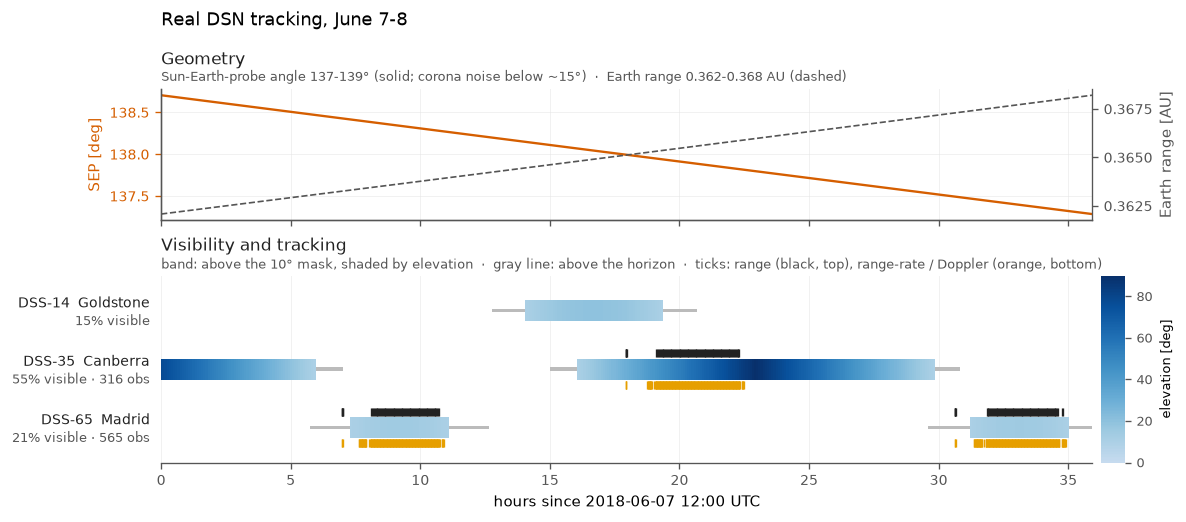

In [26]:
import glob

real_passes = sorted(glob.glob("../supplementary/supp_data/measurements/radiometric/orex_beno_2018_15[89]_*.json"))
real_grid = scb.EpochArray.interval(scb.SpiceManager.utc2et("2018-06-07T12:00:00"),
                                    scb.SpiceManager.utc2et("2018-06-09T00:00:00"), dt=scb.ArrayWUnits(5, minute), sys="TDB")
plot_tracking_timeline({name: scb.GroundStation(name) for name in ["DSS-14", "DSS-35", "DSS-65"]},
                       scb.Spacecraft("OSIRIS-REx (flight)", -64), real_grid,
                       observations=epochs_from_tracking_files(real_passes), title="Real DSN tracking, June 7-8");

# Measurement editing

`MeasurementEditing.huber_mad_filter` is the editor chapter 9 uses on raw data: per pass, it removes a robust (Huber) linear trend from the residuals, then flags points beyond `n_sigma` times a robust scale (the median absolute deviation × 1.4826), and re-estimates σ from the points it keeps. Unlike the other editing methods it has no preview figure. `plot_editing` is that preview: called on an editor **before** the filter runs, it shows the residuals, the trend of each pass, the acceptance band, which points the filter would flag and which were flagged before, and the σ it would re-estimate.

The flags and the σ come from the library's own evaluation step (`_huber_mad_evaluate`, which changes nothing), so the plot cannot disagree with the filter; the trend and the scale are recomputed for drawing, and the plot warns if they would flag different points.

Chapter 9's real DSS-35 pass, with residuals against the flight reconstruction:

In [27]:
%%capture build_log
from pathlib import Path

import trk234  # 🔵 TODO: tutorial-side TRK-2-34 loader (chapter 9)
from scenario import orex_flight

trk_file = Path("../supplementary/supp_data/measurements/radiometric/orex_beno_2018_159_054533_2018_159_104001_35.json")
media_dir = Path("../supplementary/supp_data/measurements/media_correction")
trk = trk234.load(trk_file)
dss35 = scb.GroundStation(trk234.station_name(trk))
doppler = scb.DopplerReal("DSS-35 Doppler", dss35, sigma=scb.ArrayWUnits(1e-3, 1 / sec), meas_bias=0.0,
                          computed_measurements_dict=trk234.doppler_aux_data(trk))
ranging = scb.SequentialRangingReal("DSS-35 ranging", dss35, sigma=scb.ArrayWUnits(0.5, km / km), meas_bias=0.0,
                                    computed_measurements_dict=trk234.sranging_aux_data(trk))
observed = {doppler: doppler.observed_measurements(str(trk_file), meas_name="2W_doppler", units=1 / sec),
            ranging: ranging.observed_measurements(str(trk_file), meas_name="2W_sranging", units=km / km)}
for model, obs in observed.items():
    model.media_corrections = trk234.media_corrections(dss35, obs[0][0], str(media_dir / "1972_001_2048_001_tro_modified.json"),
                                                       str(media_dir), f"{model.name} media")
editor = scb.MeasurementEditing([model.generate_measurement_dataset(dataset_name=model.name, target=orex_flight,
                                                                    observed_meas=obs)
                                 for model, obs in observed.items()])

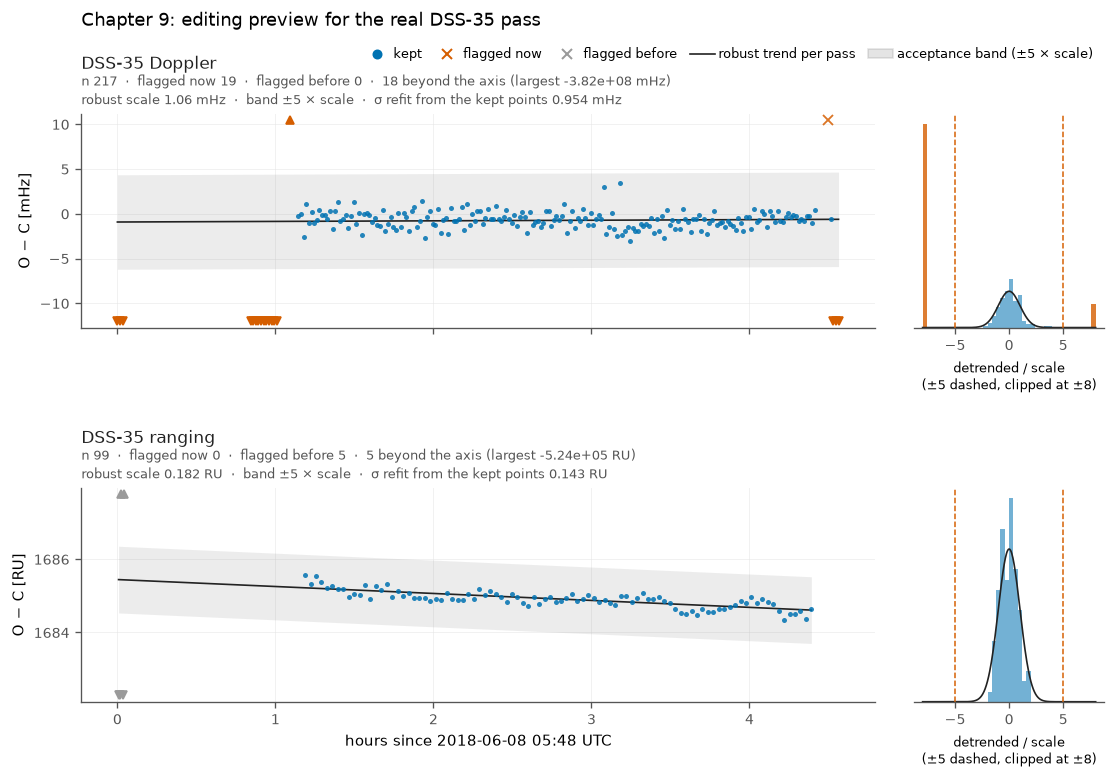

In [28]:
from plotting_prototype import plot_editing

plot_editing(editor, n_sigma=5.0, title="Chapter 9: editing preview for the real DSS-35 pass");

- **Doppler:** 19 points would be flagged. the first 15 of the pass (at −382 kHz, about −6 kHz and +3.7 kHz, still unexplained: chapter 9's 🟠 CHECK) and 3 at the end lie far beyond the axis and are drawn as edge markers; one more at the end is inside the axis but outside the band. The kept points scatter about a nearly flat trend with a robust scale of about 1 mHz, and the σ re-estimated from them is 0.95 mHz.
- **Ranging:** no new flags; the 5 rows flagged before are the no-data rows of the file. The residuals sit on a constant offset of about 1685 RU with a slight trend, which the per-pass detrend absorbs: the filter judges each pass by its own scatter, not by its offset, and the re-estimated σ (0.14 RU) is a third of the assumed 0.5 RU.

Running the filter afterwards gives the same flags:

In [29]:
flags_before = {name: int(flags.sum()) for name, flags in editor.outlier_flags.items()}
refit = editor.huber_mad_filter(n_sigma=5.0)
for name, flags in editor.outlier_flags.items():
    print(f"{name:15s} flagged {flags_before[name]} → {int(flags.sum())}   σ refit {refit[name]:.3g}")

[MeasurementEditing] Huber/MAD (5.0x): 19 new outliers flagged in 'DSS-35 Doppler'.
[MeasurementEditing] Huber/MAD (5.0x): 0 new outliers flagged in 'DSS-35 ranging'.
DSS-35 Doppler  flagged 0 → 19   σ refit 0.000954
DSS-35 ranging  flagged 5 → 5   σ refit 0.143
